SETUP

Dependencies

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import re
from scipy.optimize import curve_fit
from astropy.cosmology import FlatLambdaCDM

File paths

In [3]:
# Current working directory
print("Working directory:", Path.cwd())

# Location of SNooPy output files
data_dir = Path("../output snoopy")

# Find all supernova summary files
summary_files = sorted(data_dir.glob("*_summary.txt"))

print(f"\nFound {len(summary_files)} supernova summary files:\n")

for file in summary_files:
    print(file.name)

Working directory: c:\Users\edwar\Projects\Supernovae\supernova-lightcurve-analysis\notebooks

Found 4 supernova summary files:

SN2019np_summary.txt
SN2026aaiv_summary.txt
SN2026acna_summary.txt
SN2026aeiv_summary.txt


Extracting the data 

In [4]:
def extract_sn_data(file):

    # Read the summary file
    text = file.read_text(encoding="utf-8")

    # Supernova name from filename
    name = file.stem.replace("_summary", "")

    # Extract CMB-frame redshift
    z_match = re.search(r"zcmb\s*=\s*([\d.]+)", text)

    # Extract distance modulus and uncertainties
    dm_match = re.search(
        r"DM\s*=\s*([\d.]+)\s*\+/-\s*([\d.]+)\s*\+/-\s*([\d.]+)",
        text
    )

    # Skip files with missing values
    if not z_match or not dm_match:
        return None

    return {
        "SN": name,
        "z_CMB": float(z_match.group(1)),
        "DM": float(dm_match.group(1)),
        "DM_stat": float(dm_match.group(2)),
        "DM_sys": float(dm_match.group(3))
    }

In [5]:
# Extract data from all summary files
sn_data = []

for file in summary_files:

    result = extract_sn_data(file)

    if result is not None:
        sn_data.append(result)

# Convert to a pandas DataFrame
df = pd.DataFrame(sn_data)

# Display the results
display(df)

,SN,z_CMB,DM,DM_stat,DM_sys
0,SN2019np,0.0052,32.311,0.020,0.085
1,SN2026aaiv,0.0016,30.717,0.031,0.086
2,SN2026acna,0.0164,33.660,0.137,0.141
3,SN2026aeiv,0.0076,32.192,0.104,0.229


Distance Calculations

In [6]:
# Calculate luminosity distance (Mpc)
df["D_L"] = 10**((df["DM"] - 25) / 5)


# Propagate statistical uncertainty
df["D_L_stat"] = (
    np.log(10) / 5 * df["D_L"] * df["DM_stat"]
)

# Propagate systematic uncertainty
df["D_L_sys"] = (
    np.log(10) / 5 * df["D_L"] * df["DM_sys"]
)


display(df)

,SN,z_CMB,DM,DM_stat,DM_sys,D_L,D_L_stat,D_L_sys
0,SN2019np,0.0052,32.311,0.020,0.085,28.986782,0.266978,1.134657
1,SN2026aaiv,0.0016,30.717,0.031,0.086,13.912334,0.198613,0.550991
2,SN2026acna,0.0164,33.660,0.137,0.141,53.951062,3.403817,3.503199
3,SN2026aeiv,0.0076,32.192,0.104,0.229,27.441004,1.314253,2.893884


Hubble Diagram

In [7]:
# Combined distance modulus uncertainty
df["DM_err"] = np.sqrt(
    df["DM_stat"]**2 + df["DM_sys"]**2
)

display(df[["SN", "z_CMB", "DM", "DM_err"]])

,SN,z_CMB,DM,DM_err
0,SN2019np,0.0052,32.311,0.087321
1,SN2026aaiv,0.0016,30.717,0.091417
2,SN2026acna,0.0164,33.660,0.196596
3,SN2026aeiv,0.0076,32.192,0.251509


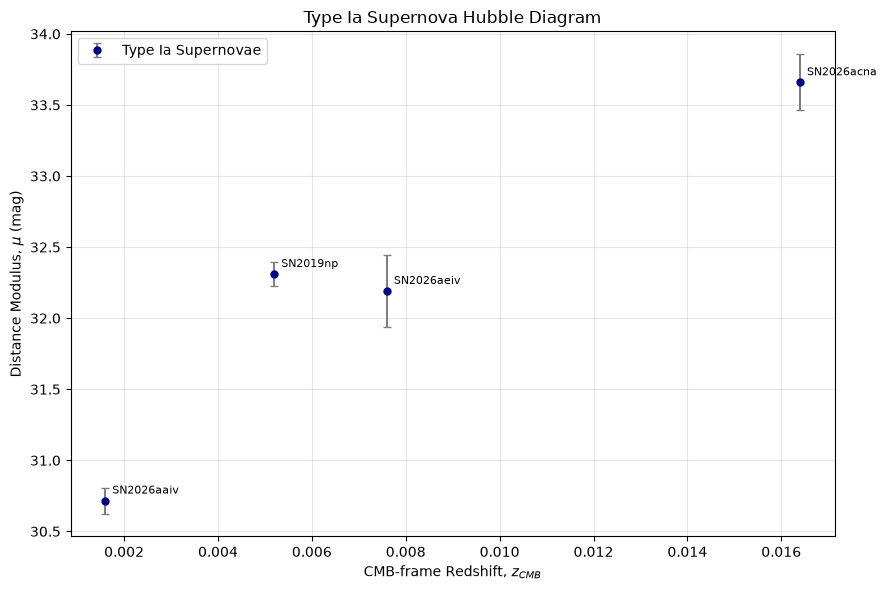

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))

# Plot supernova data with uncertainty bars
ax.errorbar(
    df["z_CMB"],
    df["DM"],
    yerr=df["DM_err"],
    fmt="o",
    capsize=3,
    markersize=5,
    color="navy",
    ecolor="grey",
    label="Type Ia Supernovae"
)

# Label individual supernovae
for _, row in df.iterrows():
    ax.annotate(
        row["SN"],
        (row["z_CMB"], row["DM"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

# Axis labels
ax.set_xlabel("CMB-frame Redshift, $z_{CMB}$")
ax.set_ylabel("Distance Modulus, $\\mu$ (mag)")

ax.set_title("Type Ia Supernova Hubble Diagram")

# Formatting
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

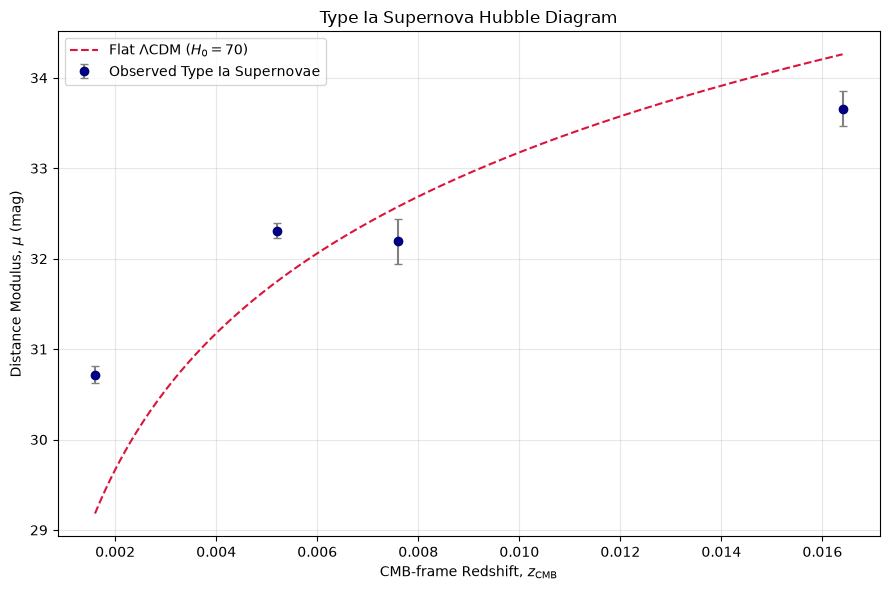

In [9]:
# Define cosmological model
cosmo = FlatLambdaCDM(
    H0=70,
    Om0=0.3
)

# Generate redshift values for theoretical curve
z_model = np.linspace(
    df["z_CMB"].min(),
    df["z_CMB"].max(),
    300
)

# Calculate theoretical distance modulus
mu_model = cosmo.distmod(z_model).value

# Plot observed data
fig, ax = plt.subplots(figsize=(9, 6))

ax.errorbar(
    df["z_CMB"],
    df["DM"],
    yerr=df["DM_err"],
    fmt="o",
    capsize=3,
    color="navy",
    ecolor="grey",
    label="Observed Type Ia Supernovae"
)

# Plot theoretical prediction
ax.plot(
    z_model,
    mu_model,
    color="crimson",
    linestyle="--",
    label=r"Flat $\Lambda$CDM ($H_0=70$)"
)

ax.set_xlabel(r"CMB-frame Redshift, $z_{\mathrm{CMB}}$")
ax.set_ylabel(r"Distance Modulus, $\mu$ (mag)")
ax.set_title("Type Ia Supernova Hubble Diagram")

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

Hubble Residues

,SN,z_CMB,DM,DM_model,DM_residual,DM_err
0,SN2019np,0.0052,32.311,31.747347,0.563653,0.087321
1,SN2026aaiv,0.0016,30.717,29.181903,1.535097,0.091417
2,SN2026acna,0.0164,33.660,34.260100,-0.600100,0.196596
3,SN2026aeiv,0.0076,32.192,32.575400,-0.383400,0.251509


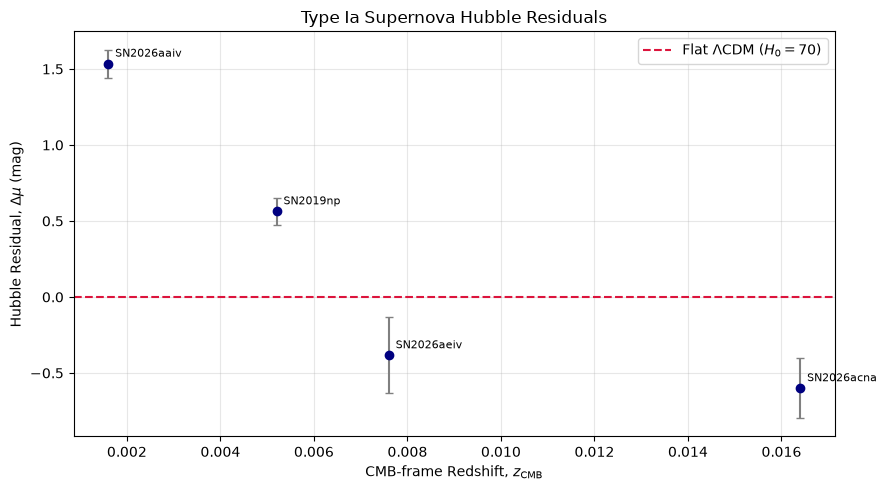

In [10]:
# Calculate theoretical distance modulus at each observed redshift
df["DM_model"] = cosmo.distmod(df["z_CMB"].to_numpy()).value

# Calculate Hubble residuals
df["DM_residual"] = df["DM"] - df["DM_model"]

# Display results
display(
    df[["SN", "z_CMB", "DM", "DM_model", "DM_residual", "DM_err"]]
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.errorbar(
    df["z_CMB"],
    df["DM_residual"],
    yerr=df["DM_err"],
    fmt="o",
    capsize=3,
    color="navy",
    ecolor="grey"
)

# Zero residual reference line
ax.axhline(
    0,
    color="crimson",
    linestyle="--",
    label=r"Flat $\Lambda$CDM ($H_0=70$)"
)

# Label each supernova
for _, row in df.iterrows():
    ax.annotate(
        row["SN"],
        (row["z_CMB"], row["DM_residual"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlabel(r"CMB-frame Redshift, $z_{\mathrm{CMB}}$")
ax.set_ylabel(r"Hubble Residual, $\Delta\mu$ (mag)")
ax.set_title("Type Ia Supernova Hubble Residuals")

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

The above plots are preliminary plots. Peculiar velocities need to be acounted for. This will be investigated within the coming weeks.